# EN3160 ASSIGNMENT 02
## FITTING AND ALIGNMENT

**Name:** M.R.A.Hakam  
**Index number:** 230224V

In [1]:
import json
from pathlib import Path

import cv2 as cv
import numpy as np
from scipy.ndimage import maximum_filter
from IPython.display import HTML, Image, display

ROOT = Path.cwd()
synthetic = json.loads((ROOT / "results/q1/synthetic_circle.json").read_text())
sunflower = json.loads((ROOT / "results/q1/sunflower_circles.json").read_text())
line = json.loads((ROOT / "results/q2/line_fit.json").read_text())
circle = json.loads((ROOT / "results/q2/circle_fit.json").read_text())


### QUESTION 1  BLOB DETECTION

#### SYNTHETIC CIRCLE

The LoG filter was first checked using a circle with radius 14 and centre at (35, 35). The selected sigma was 10 and the estimated radius was 14.14 pixels, giving a radius error of 0.14 pixels

The same filter was then applied at several sizes to the sunflower image

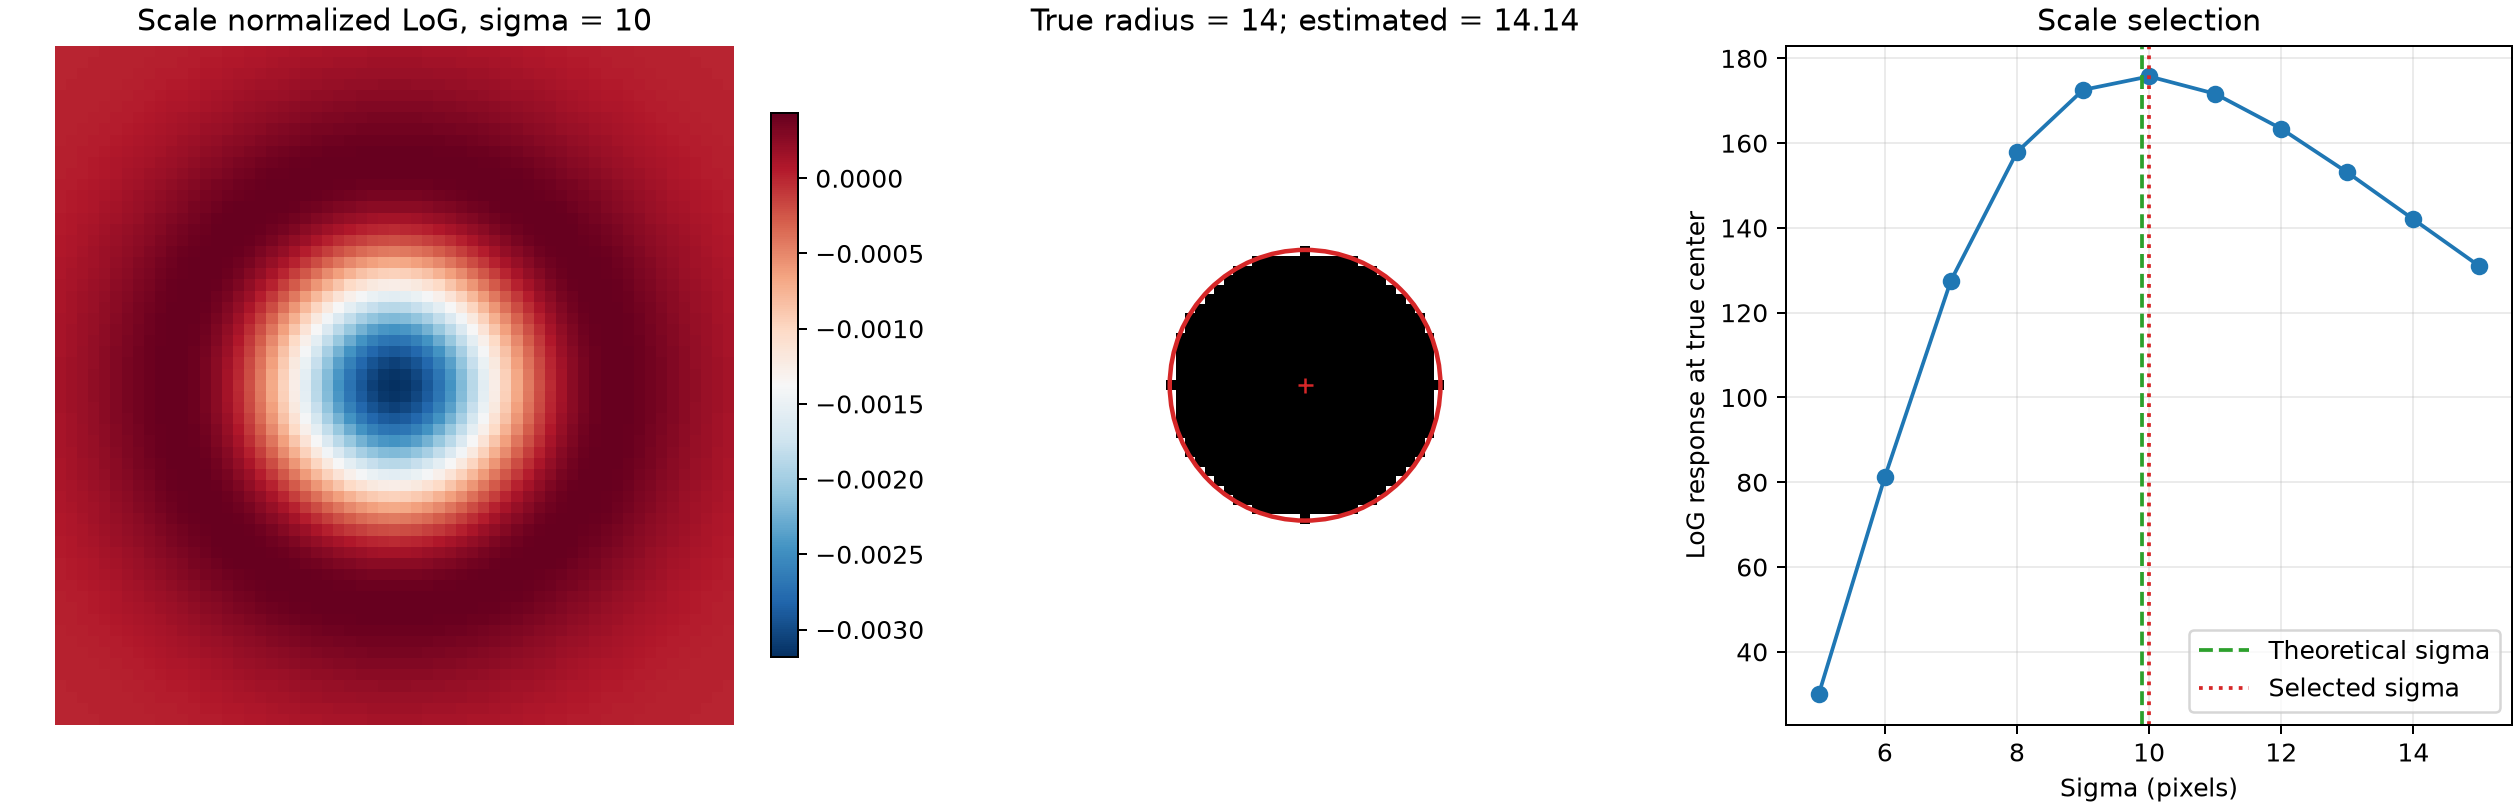

In [2]:
def normalized_log_kernel(sigma):
    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError("Sigma must be positive and finite")

    half_width = int(np.ceil(3 * sigma))
    coordinates = np.arange(-half_width, half_width + 1, dtype=np.float64)
    x, y = np.meshgrid(coordinates, coordinates)
    squared_distance = x**2 + y**2
    kernel = (
        (squared_distance / sigma**2 - 2)
        * np.exp(-squared_distance / (2 * sigma**2))
        / (2 * np.pi * sigma**2)
    )
    return kernel.astype(np.float32)

display(Image(filename=str(ROOT / "results/q1/synthetic_circle.png"), width=620))


In [3]:
image = cv.imread(str(ROOT / "images/the_berry_farms_sunflower_field.jpeg"), cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
sigmas = np.array(sunflower["sigma_values"])
scale_space = np.stack([cv.filter2D(gray, cv.CV_32F, normalized_log_kernel(sigma)) for sigma in sigmas], axis=2)
maxima = (scale_space == maximum_filter(scale_space, size=3, mode="nearest")) & (scale_space >= sunflower["response_threshold"])
maxima[:, :, [0, -1]] = False
print(f"Sigma range: {sigmas[0]:g} to {sigmas[-1]:g} with step 0.5")
print(f"Final detected circles: {sunflower['detected_count']}")


Sigma range: 1 to 12 with step 0.5
Final detected circles: 65


#### SUNFLOWER DETECTION

Positive LoG responses were used to find the dark flower centres. Each candidate was compared with its neighbours in image position and scale. The response threshold was 0.22 after scaling the image values to 0 to 1

A yellow pixel check around each candidate removed many tree and leaf responses. At least 35% of the ring from one radius to 2.2 radii had to pass this check

The stronger response was kept when circle centres were closer than 0.6 times the sum of their radii. Circles crossing the image edge and peaks at the first or last scale were excluded

#### RESULTS

The radii below describe the dark centres and do not include the outer petals

Circle,x,y,Radius,Sigma
1,282,338,10.61,7.5
2,106,255,8.49,6
3,179,327,8.49,6
4,178,261,7.78,5.5
5,161,290,6.36,4.5


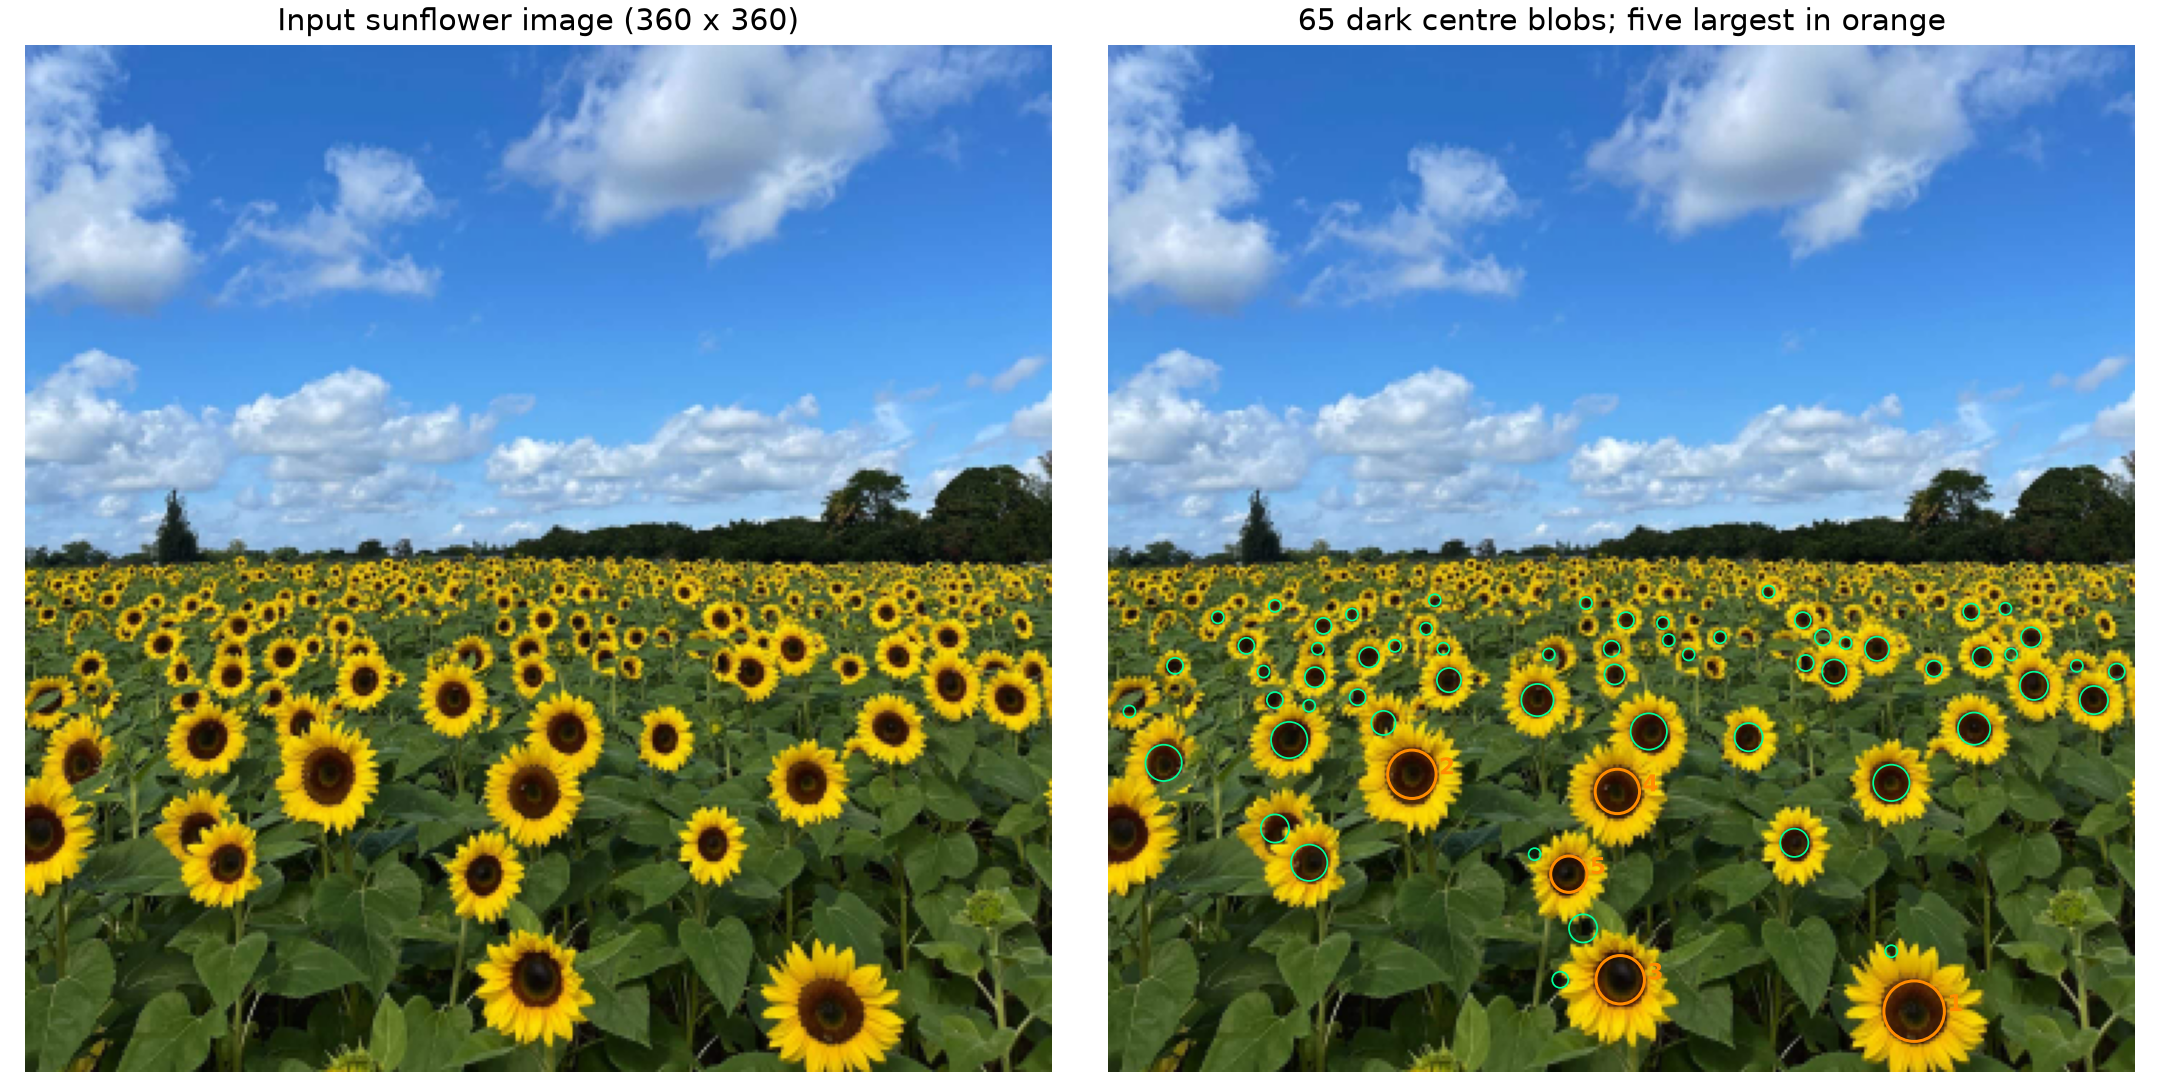

In [4]:
rows = "".join(f"<tr><td>{i}</td><td>{c['x']}</td><td>{c['y']}</td><td>{c['radius']:.2f}</td><td>{c['sigma']:g}</td></tr>" for i, c in enumerate(sunflower["largest_circles"], 1))
display(HTML("<table><tr><th>Circle</th><th>x</th><th>y</th><th>Radius</th><th>Sigma</th></tr>" + rows + "</table>"))
display(Image(filename=str(ROOT / "results/q1/sunflower_detection.png"), width=720))


There are 65 detections and the five largest are marked in orange. The largest centre is at (282, 338) with radius 10.61 pixels. All positions and radii use the reduced 360 by 360 image

The filter finds clear foreground centres but misses some small distant flowers. Nearby flowers can also merge during duplicate removal

### QUESTION 2  LINE AND CIRCLE FITTING

#### LINE FITTING

The point generator uses seed 0 and gives 50 noisy circle points and 50 noisy line points. Two different points form a line sample and perpendicular distance is used to find its inliers

The line is written as ax + by = d with a squared plus b squared equal to 1. The line threshold is 1.4, the minimum consensus is 40 and the loop uses 500 samples. This threshold is about twice the expected perpendicular noise of 0.71

In [5]:
def fit_line(points):
    center = points.mean(axis=0)
    _, _, vectors = np.linalg.svd(points - center, full_matrices=False)
    normal = vectors[-1]
    model = np.append(normal, normal @ center)
    return -model if model[2] < 0 else model

def circle_from_points(points):
    offsets = points[1:] - points[0]
    matrix = 2 * offsets
    if np.linalg.cond(matrix) > 1e8:
        raise ValueError("The circle sample is too close to a straight line")
    right = np.sum(offsets**2, axis=1)
    relative_center = np.linalg.solve(matrix, right)
    center = points[0] + relative_center
    radius = np.linalg.norm(relative_center)
    model = np.append(center, radius)
    if not np.isfinite(model).all() or radius < 1e-10:
        raise ValueError("The circle sample is invalid")
    return model

def circle_errors(points, model):
    return np.abs(np.linalg.norm(points - model[:2], axis=1) - model[2])


#### CIRCLE FITTING

The line consensus is removed before fitting the circle. Three points form a circle sample and radial distance is used to find its inliers. The circle threshold is 1.25, the minimum consensus is 30 and the loop uses 500 samples. This threshold is twice the radial noise level of 0.625 in the point generator

Both loops prefer the larger consensus and use the smaller mean squared error to break a tie. The line is refined by total least squares and the circle is refined by minimizing squared radial errors

#### RESULTS

The winning samples and their models are shown together with the refined models

Line parameters (a, b, d): [0.721  0.693  1.5724]
Line inliers: 54 of 100
Circle parameters (x, y, radius): [1.8982 3.0101 9.8314]
Circle inliers: 44 of 46


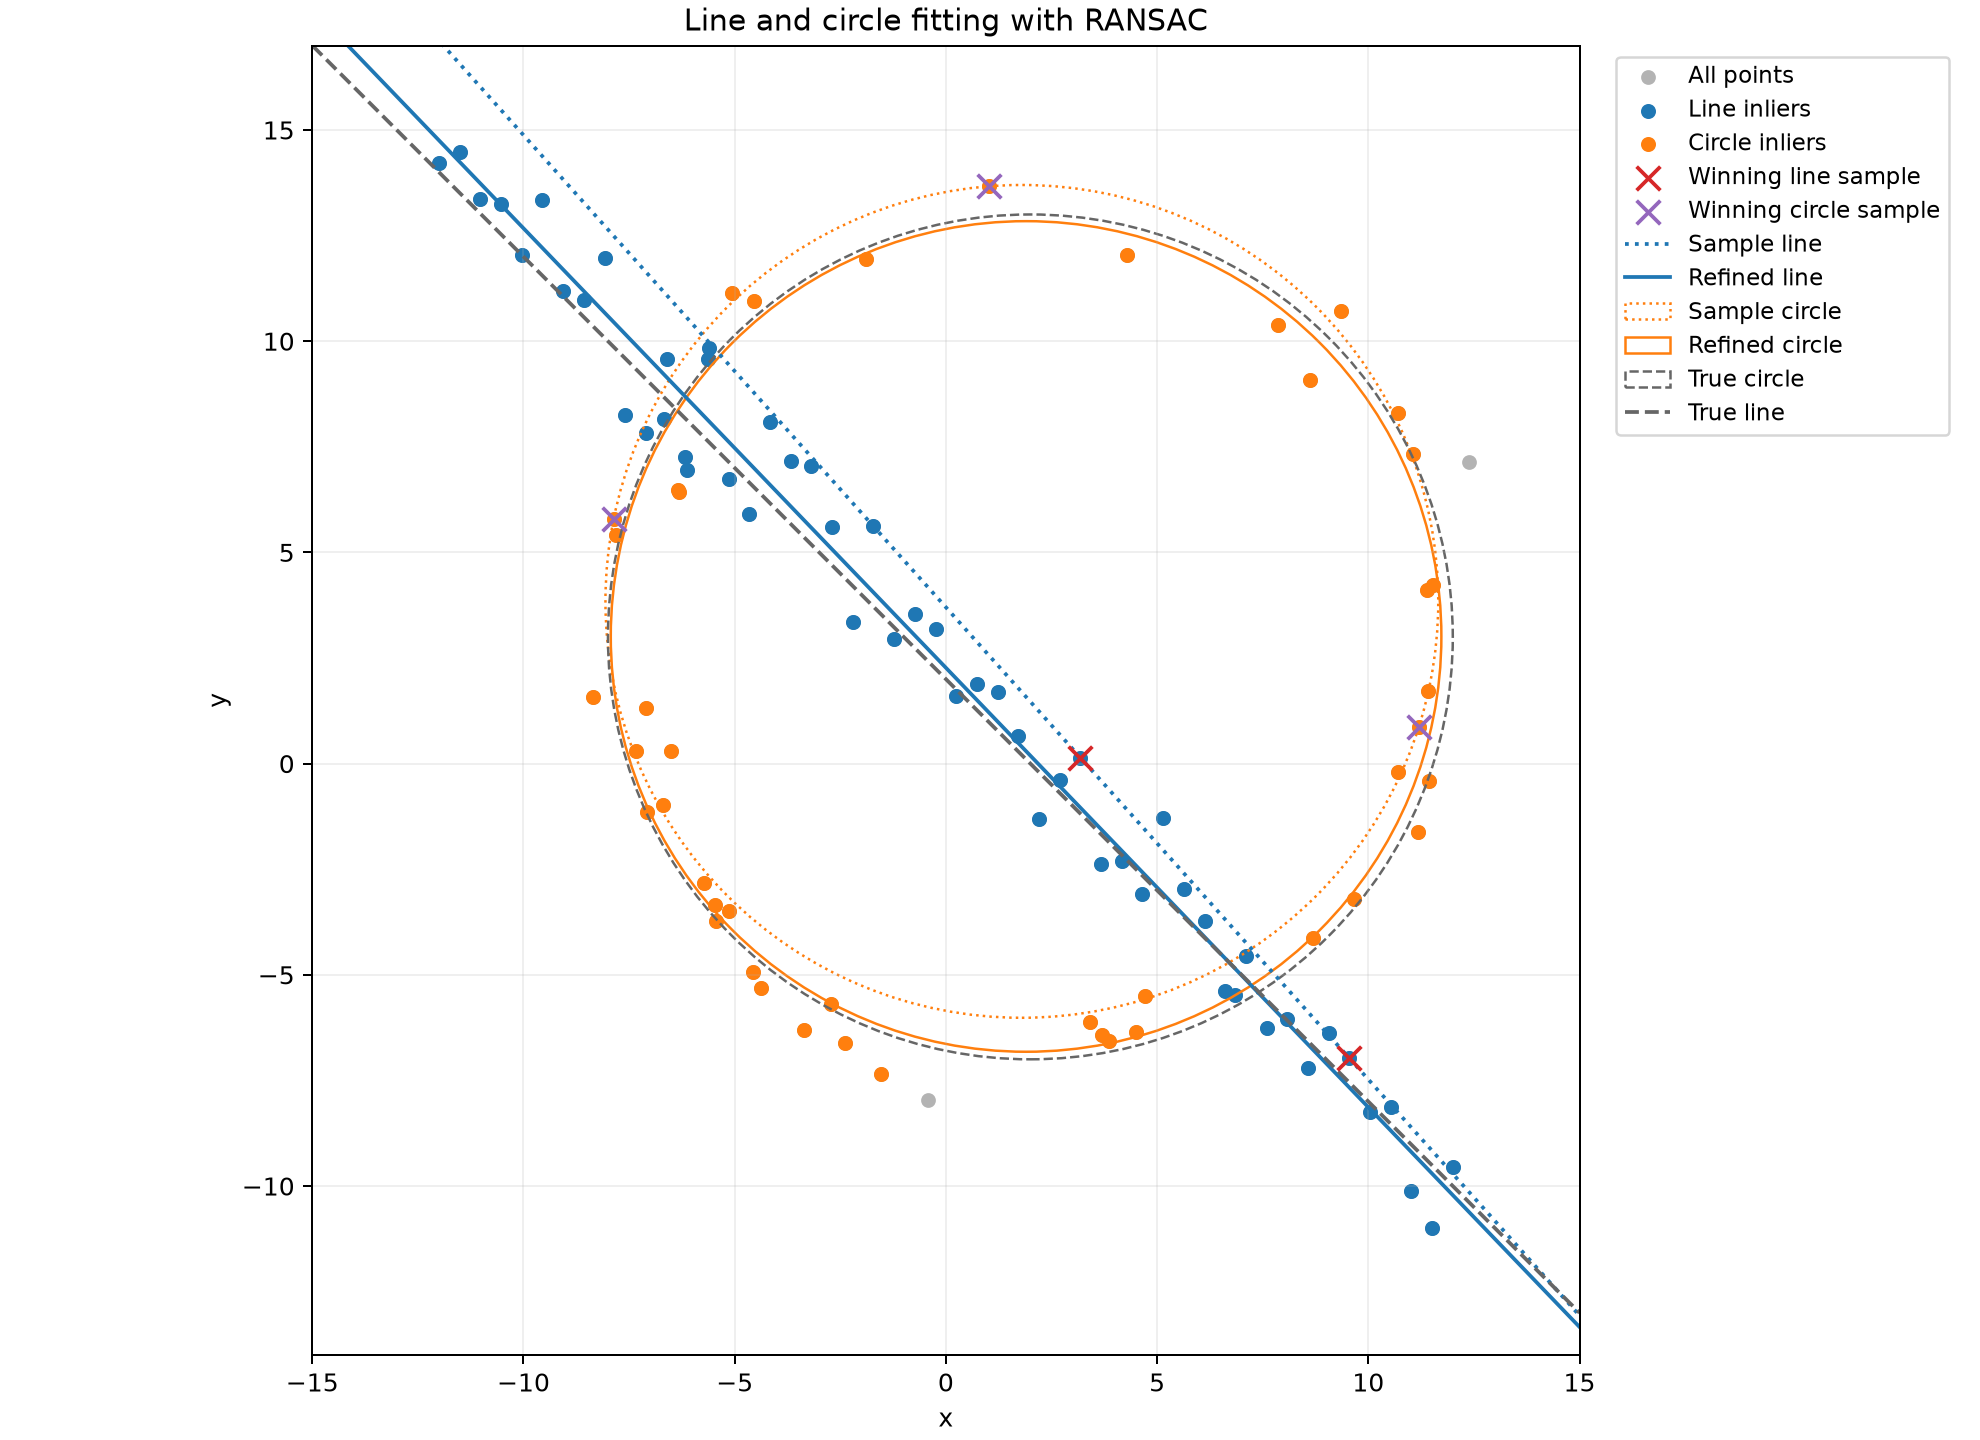

In [6]:
points = np.loadtxt(ROOT / "results/q2/points.csv", delimiter=",", skiprows=1)
line_model = np.array(line["model"])
circle_model = np.array(circle["model"])
line_indices = np.array(line["inlier_indices"])
circle_indices = np.array(circle["inlier_indices"])
print(f"Line parameters (a, b, d): {line_model.round(4)}")
print(f"Line inliers: {line['inlier_count']} of {len(points)}")
print(f"Circle parameters (x, y, radius): {circle_model.round(4)}")
print(f"Circle inliers: {circle['inlier_count']} of {circle['input_point_count']}")
display(Image(filename=str(ROOT / "results/q2/line_and_circle.png"), width=620))


The line consensus contains all 50 generated line points and four nearby circle points. Those four circle points are close to the line and are removed with its consensus. The circle fit uses the remaining 46 points and keeps 44 as inliers

The estimated circle centre is (1.90, 3.01) and its radius is 9.83, compared with the true centre (2, 3) and radius 10. The centre error is about 0.10 and the radius error is about 0.17. The line inlier RMSE is 0.67 and the circle inlier RMSE is 0.53

The generated labels were used only to check the result afterwards and were not used by RANSAC

#### FITTING THE CIRCLE FIRST

The order was reversed using the same 100 points and the same distance thresholds, minimum consensus sizes, sample counts and random seeds


In [7]:
from q2_fitting import ransac_circle, ransac_line, save_order_comparison

def fit_circle_then_line(points):
    circle = ransac_circle(points)
    circle["input_point_count"] = len(points)
    remaining = np.setdiff1d(np.arange(len(points)), circle["inlier_indices"])
    line = None
    failure = None
    if len(remaining) < 40:
        failure = "Too few points remain for the minimum line consensus of 40"
    else:
        try:
            line = ransac_line(points[remaining])
        except RuntimeError as error:
            failure = str(error)
    if line is not None:
        for name in ("sample_indices", "sample_inlier_indices", "inlier_indices"):
            line[name] = remaining[line[name]]
        line["input_point_count"] = len(remaining)
        line["remaining_point_indices"] = remaining
    return {
        "circle": circle,
        "line": line,
        "remaining_point_indices": remaining,
        "line_failure": failure,
    }

reverse = fit_circle_then_line(points)
comparison = save_order_comparison(points, line, circle, reverse)


Circle first parameters (x, y, radius): [1.902  3.0176 9.8802]
Line after circle parameters (a, b, d): [0.7232 0.6907 1.6638]


Order,Line inliers,Circle inliers,Points for second fit,Line RMSE,Circle RMSE
Line then circle,54,44,46,0.671,0.531
Circle then line,41,57,43,0.589,0.571


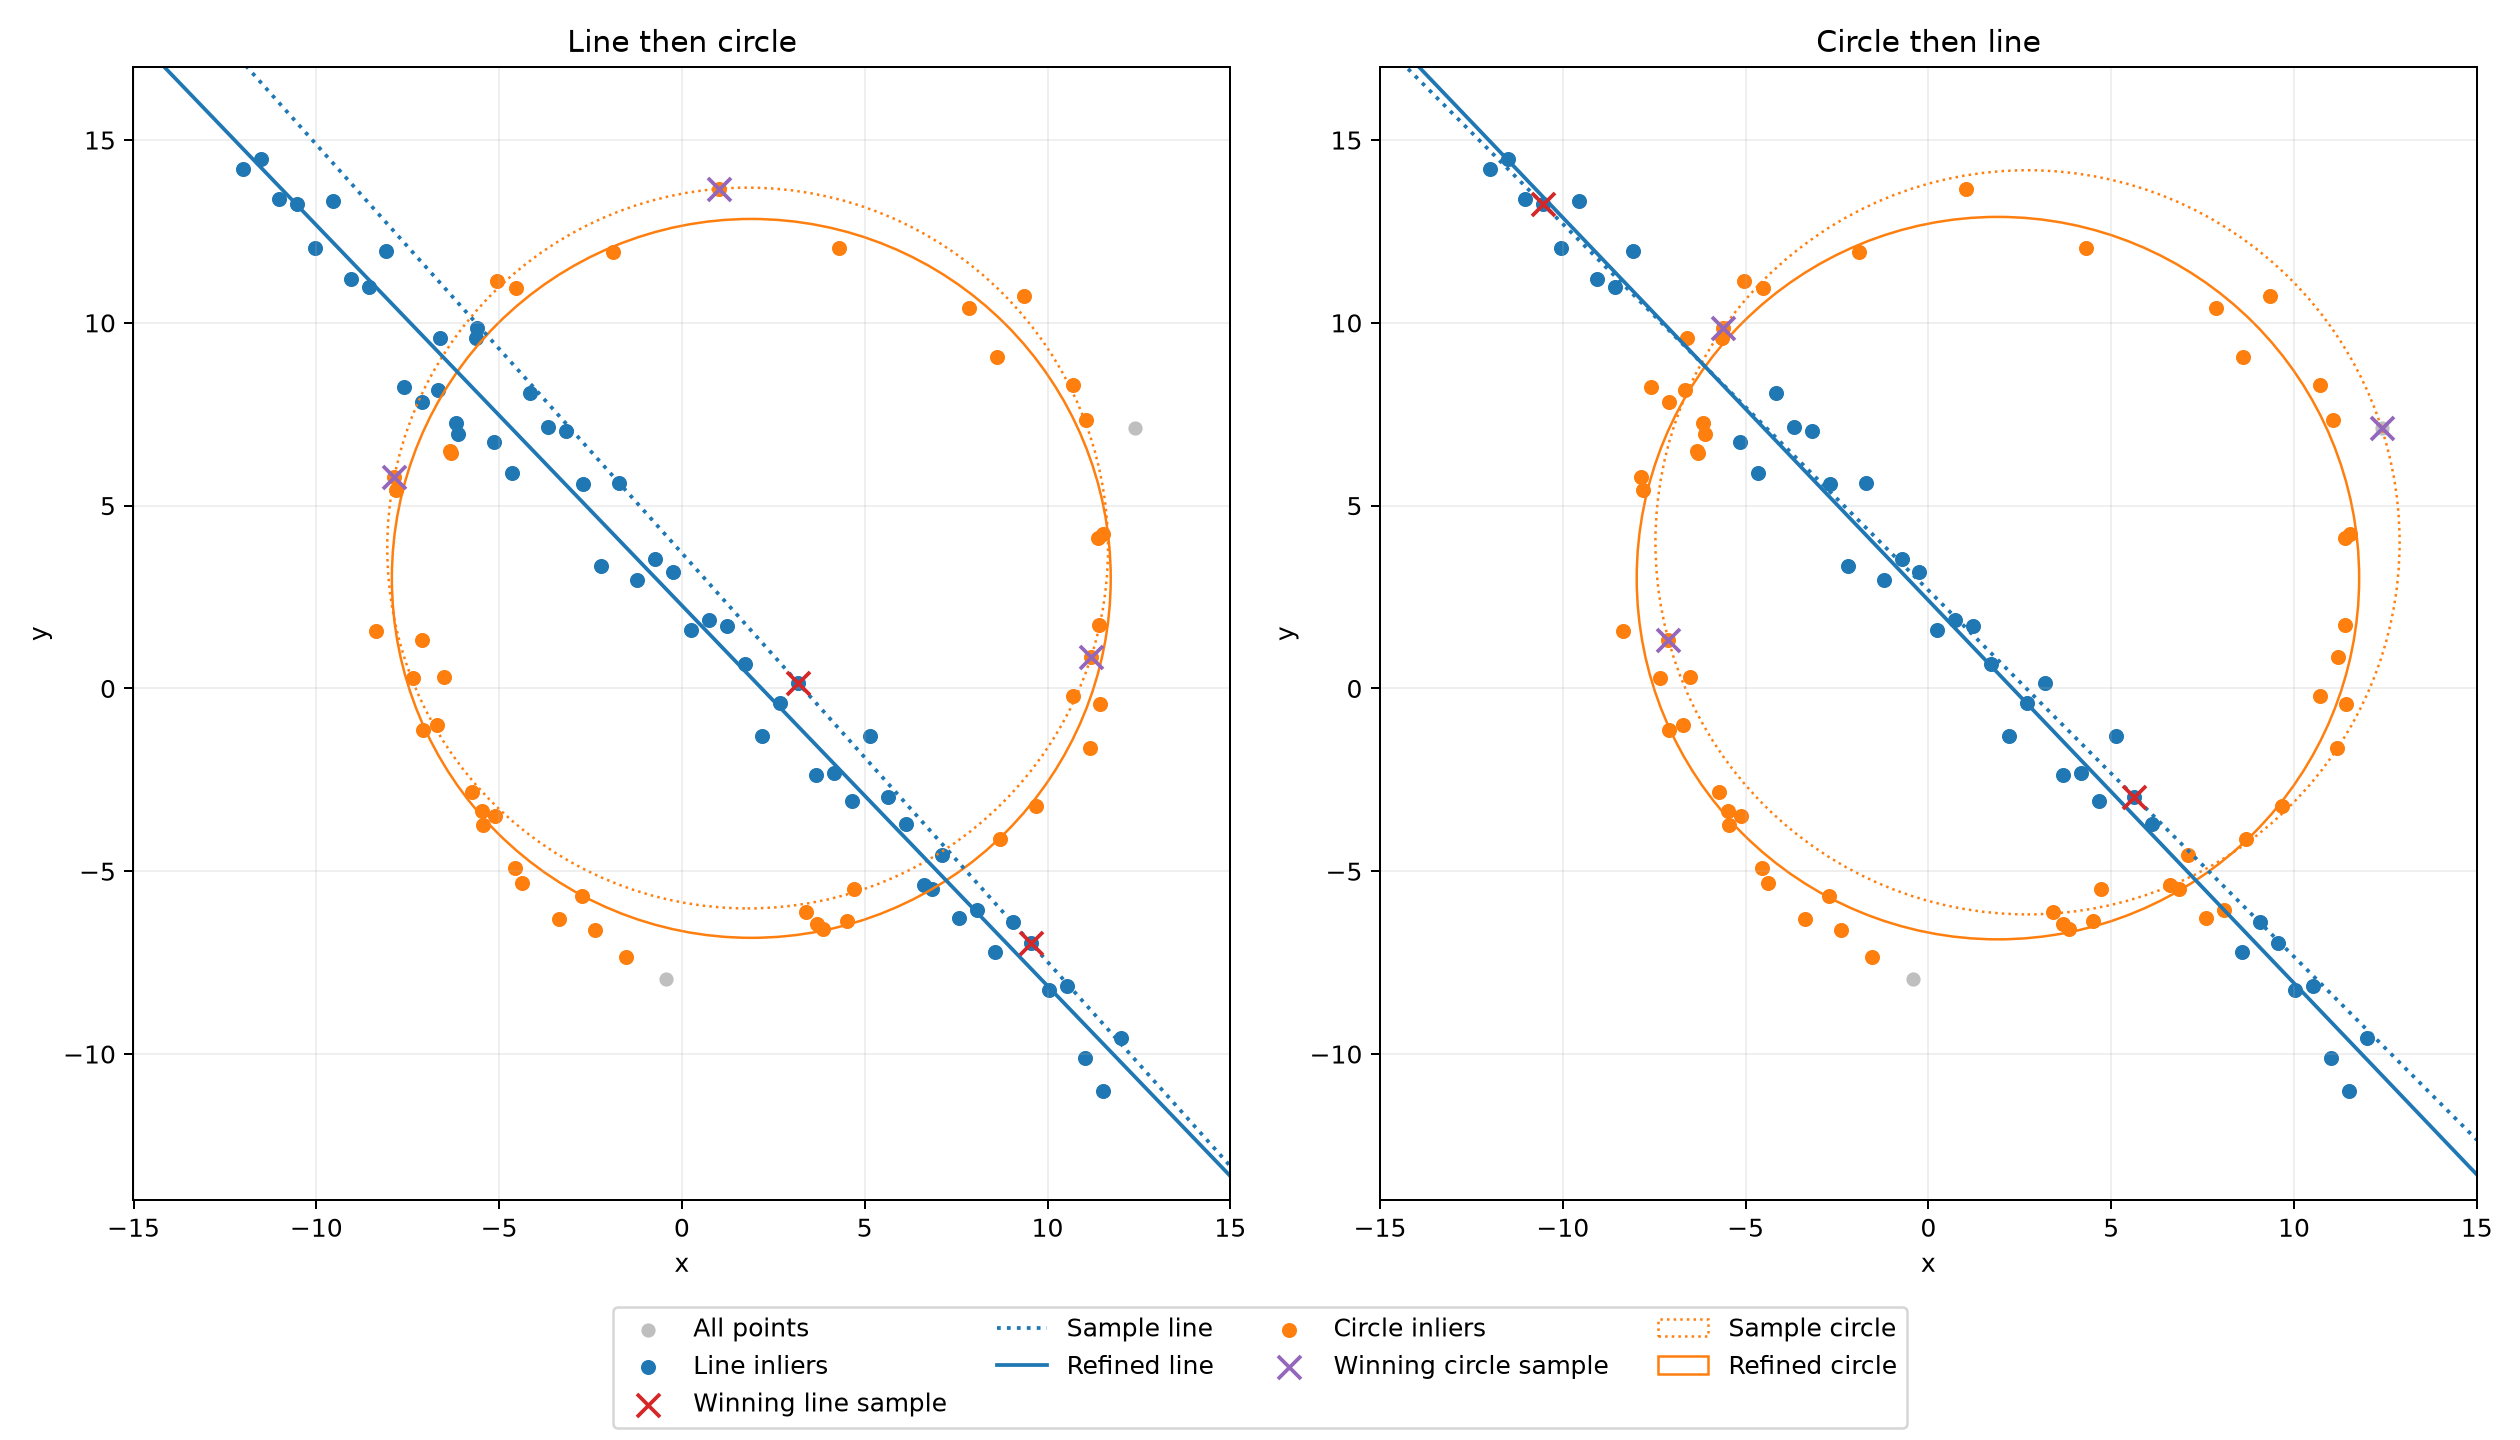

In [8]:
rows = "".join(
    f"<tr><td>{row['order']}</td><td>{row['line_inliers']}</td><td>{row['circle_inliers']}</td>"
    f"<td>{row['points_for_second_model']}</td><td>{row['line_inlier_rmse']:.3f}</td>"
    f"<td>{row['circle_inlier_rmse']:.3f}</td></tr>"
    for row in comparison["summary"]
)
display(HTML("<table><tr><th>Order</th><th>Line inliers</th><th>Circle inliers</th>"
             "<th>Points for second fit</th><th>Line RMSE</th><th>Circle RMSE</th></tr>"
             + rows + "</table>"))
print(f"Circle first parameters (x, y, radius): {reverse['circle']['model'].round(4)}")
print(f"Line after circle parameters (a, b, d): {reverse['line']['model'].round(4)}")
display(Image(filename=str(ROOT / "results/q2/fitting_order_comparison.png"), width=900))


Fitting the circle first gives 57 circle inliers and removes nine generated line points near the circle before fitting the line. The line then keeps 41 inliers from 43 remaining points

With the line fitted first, four generated circle points are removed and the circle keeps 44 inliers from 46 remaining points. Both orders recover a line and a circle close to the true models for this data, but the order changes the consensus and the data left for the second fit

A circle fitted to mixed data can accept line points near its boundary, so fitting it first can leave fewer line points and may prevent the later line fit from reaching its required consensus in other noisy samples


### QUESTION 3  FOUR POINT IMAGE COMPOSITING

#### PROVIDED IMAGE EXAMPLE

The flag is placed on a flat part of the supplied building image using four corners in the order top left, top right, bottom right and bottom left. A homography maps the flag corners to these positions

The flag is blended with opacity 0.75 inside its warped mask. The selected points and homography are saved so the result can be reproduced. Running q3_compositing.py with the select option allows the four corners to be clicked again

In [9]:
from q3_compositing import validate_corners

def composite_overlay(background, overlay, corners, opacity=0.75):
    corners = validate_corners(corners, background.shape)
    if not 0 <= opacity <= 1:
        raise ValueError("Opacity must be between zero and one")
    if overlay.ndim != 3 or overlay.shape[2] not in (3, 4):
        raise ValueError("The overlay must be a colour image")
    height, width = overlay.shape[:2]
    source = np.float32([[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]])
    homography = cv.getPerspectiveTransform(source, corners)
    if not np.isfinite(homography).all() or np.linalg.cond(homography) > 1e12:
        raise ValueError("The selected corners give an unstable homography")
    alpha = overlay[:, :, 3].astype(np.float32) / 255 if overlay.shape[2] == 4 else np.ones((height, width), np.float32)
    colours = overlay[:, :, :3].astype(np.float32) * alpha[:, :, None]
    size = (background.shape[1], background.shape[0])
    warped = cv.warpPerspective(colours, homography, size, flags=cv.INTER_LINEAR)
    coverage = cv.warpPerspective(alpha, homography, size, flags=cv.INTER_LINEAR)
    result = background.astype(np.float32) * (1 - opacity * coverage[:, :, None]) + opacity * warped
    return np.clip(np.round(result), 0, 255).astype(np.uint8), homography, coverage


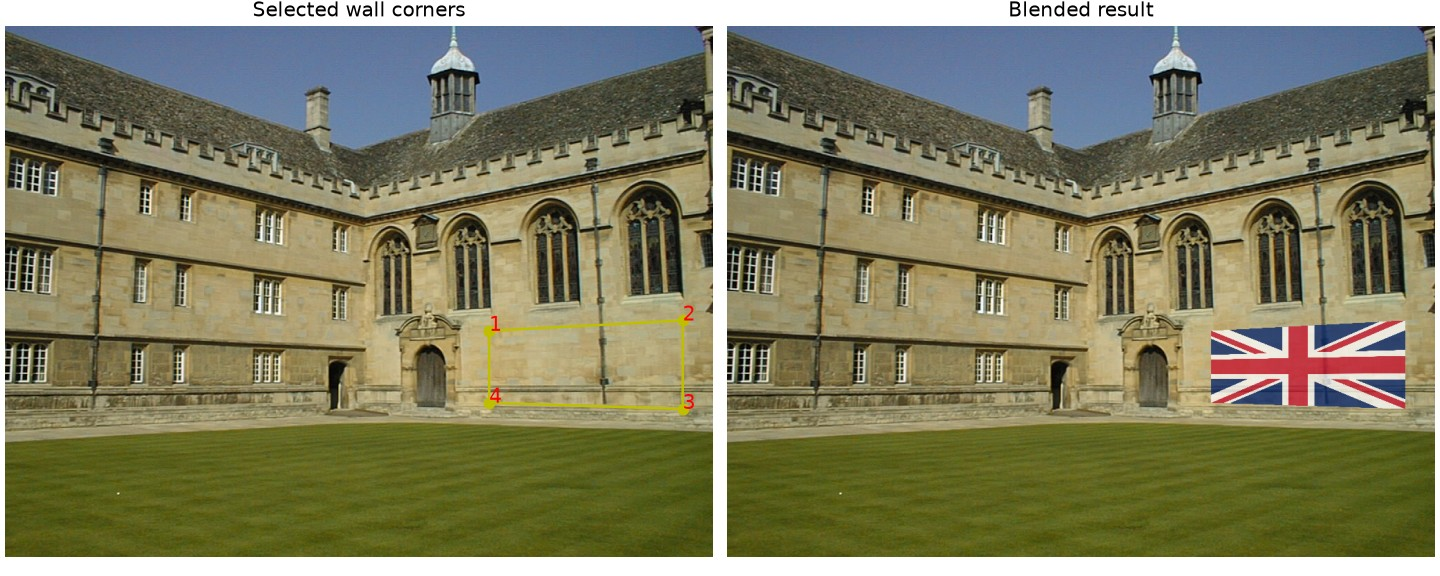

In [10]:
selection = json.loads((ROOT / "results/q3/wadham_points.json").read_text())
background = cv.imread(str(ROOT / selection["background"]))
overlay = cv.imread(str(ROOT / selection["overlay"]), cv.IMREAD_UNCHANGED)
composite, homography, coverage = composite_overlay(background, overlay, selection["corners"], selection["opacity"])
display(Image(filename=str(ROOT / "results/q3/wadham_comparison.jpg"), width=900))


The flag follows the perspective of the selected wall region. Some wall texture remains visible through the flag because the opacity is below one. Pixels outside the warped flag mask keep their original values

#### TWO CHOSEN IMAGE PAIRS

The first pair places the fruit image on a flat box face. The second pair places the butterfly image on the wall. These four images are OpenCV sample images and their source details are saved with the images

The four corners were chosen from the displayed images and saved in the same order as the building example. The opacity is 0.8 for the box and 0.85 for the wall. The select option can be used with either saved points file to choose the corners again

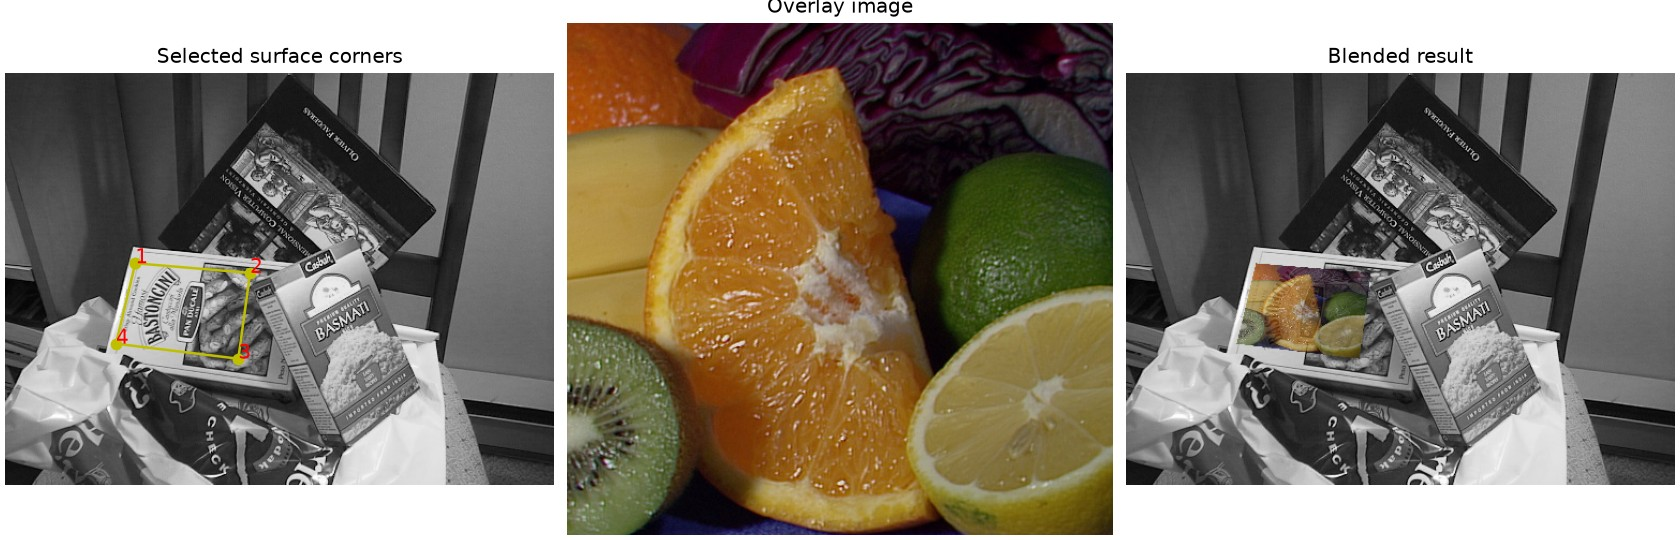

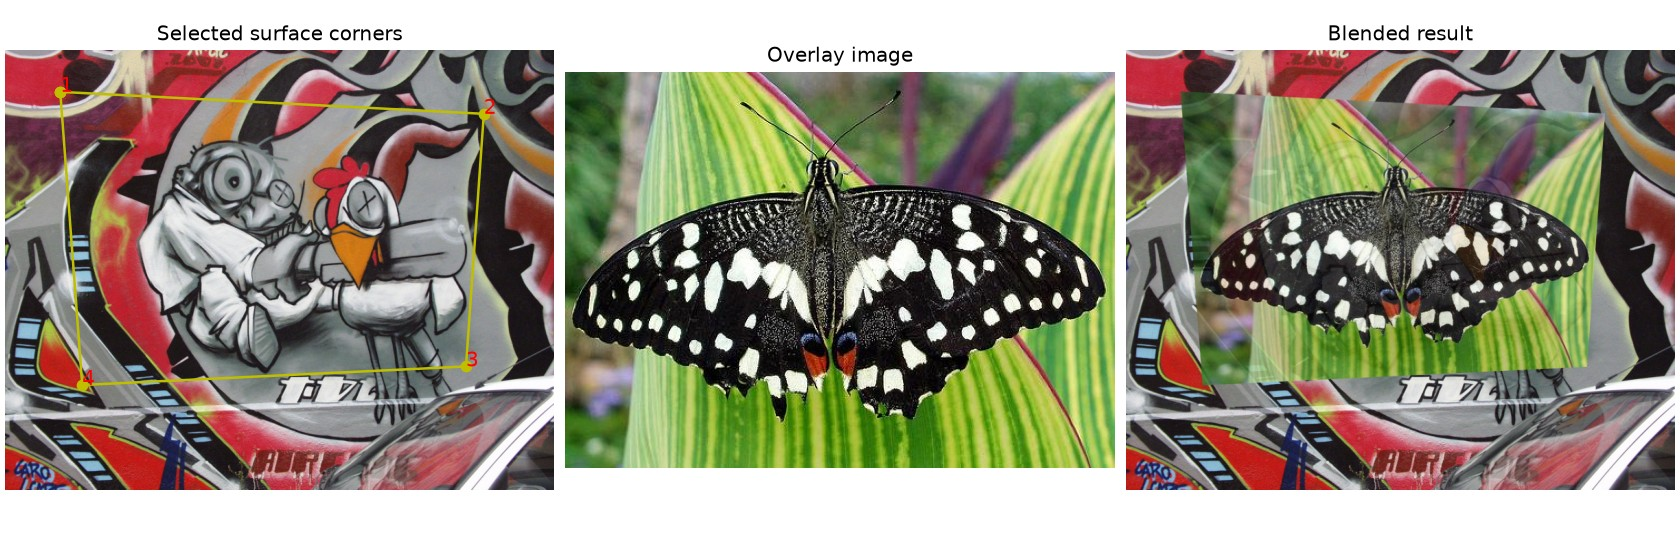

In [13]:
from q3_compositing import run_compositing

for example_name in ["box", "wall"]:
    example = run_compositing(name=example_name)
    display(Image(filename=str(ROOT / f"results/q3/{example_name}_comparison.jpg"), width=1000))


The fruit image follows the slanted box face while the butterfly image fills the selected wall region. Both results keep some of the original surface visible through blending. The surrounding pixels stay unchanged because blending is limited to the warped mask

### QUESTION 4  PCB ALIGNMENT

#### FEATURE MATCHING

SIFT descriptors are matched to AECC1.jpg using BFMatcher with L2 distance. A ratio threshold of 0.8 rejects ambiguous matches and a mutual nearest neighbour check removes repeated matches to the same reference feature

Features are detected with the longer image side reduced to 1000 pixels. Their coordinates are converted back to the original image size before estimating the homography. RANSAC uses a five pixel threshold in the reference image

The same settings are used for all five PCB images. Each match figure shows up to 80 inlier matches while the table counts all accepted matches

In [11]:
def detect_sift(image, sift, maximum_side=1000):
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    scale = min(maximum_side / max(gray.shape), 1)
    small = cv.resize(gray, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA)
    keypoints, descriptors = sift.detectAndCompute(small, None)
    sx, sy = small.shape[1] / gray.shape[1], small.shape[0] / gray.shape[0]
    keypoints = [cv.KeyPoint(point.pt[0] / sx, point.pt[1] / sy, point.size / np.sqrt(sx * sy), point.angle, point.response, point.octave, point.class_id) for point in keypoints]
    return keypoints, descriptors, gray.shape

def estimate_pcb_homography(image, reference_features, sift, ratio=0.8, threshold=5.0):
    keypoints, descriptors, _ = detect_sift(image, sift)
    reference_keypoints, reference_descriptors, reference_shape = reference_features
    if descriptors is None or reference_descriptors is None:
        raise RuntimeError("SIFT descriptors could not be found")
    matcher = cv.BFMatcher(cv.NORM_L2)
    neighbours = matcher.knnMatch(descriptors, reference_descriptors, k=2)
    reverse = {match.queryIdx: match.trainIdx for match in matcher.match(reference_descriptors, descriptors)}
    matches = [pair[0] for pair in neighbours if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance and reverse[pair[0].trainIdx] == pair[0].queryIdx]
    if len(matches) < 4:
        raise RuntimeError("At least four reliable matches are required")
    source = np.float32([keypoints[match.queryIdx].pt for match in matches])
    destination = np.float32([reference_keypoints[match.trainIdx].pt for match in matches])
    cv.setRNGSeed(0)
    homography, mask = cv.findHomography(source, destination, cv.RANSAC, threshold, maxIters=5000, confidence=0.995)
    if homography is None or mask is None or not np.isfinite(homography).all() or np.linalg.matrix_rank(homography) != 3:
        raise RuntimeError("A valid PCB homography could not be estimated")
    inliers = mask.ravel().astype(bool)
    if inliers.sum() < 4:
        raise RuntimeError("The homography has too few inliers")
    source_coverage = cv.contourArea(cv.convexHull(source[inliers])) / (image.shape[0] * image.shape[1])
    reference_coverage = cv.contourArea(cv.convexHull(destination[inliers])) / (reference_shape[0] * reference_shape[1])
    if min(source_coverage, reference_coverage) < 0.005:
        raise RuntimeError("The inliers do not cover a usable image region")
    projected = cv.perspectiveTransform(source[:, None, :], homography)[:, 0, :]
    errors = np.linalg.norm(projected - destination, axis=1)
    record = {
        "source_keypoints": len(keypoints),
        "reference_keypoints": len(reference_keypoints),
        "ratio_threshold": ratio,
        "ransac_threshold_pixels": threshold,
        "match_count": len(matches),
        "inlier_count": int(inliers.sum()),
        "inlier_rmse_pixels": float(np.sqrt(np.mean(errors[inliers] ** 2))),
        "source_inlier_coverage": source_coverage,
        "reference_inlier_coverage": reference_coverage,
        "source_points": source.tolist(),
        "reference_points": destination.tolist(),
        "inlier_mask": inliers.tolist(),
        "homography": homography.tolist(),
    }
    return record, keypoints, matches


#### MATCHES

PCB image,Filtered matches,RANSAC inliers
AAAA1.jpg,76,33
ADAD1.jpg,236,175
AECC2.jpg,1987,1881
AECC3.jpg,2156,2050
AECC4.jpg,1976,1885


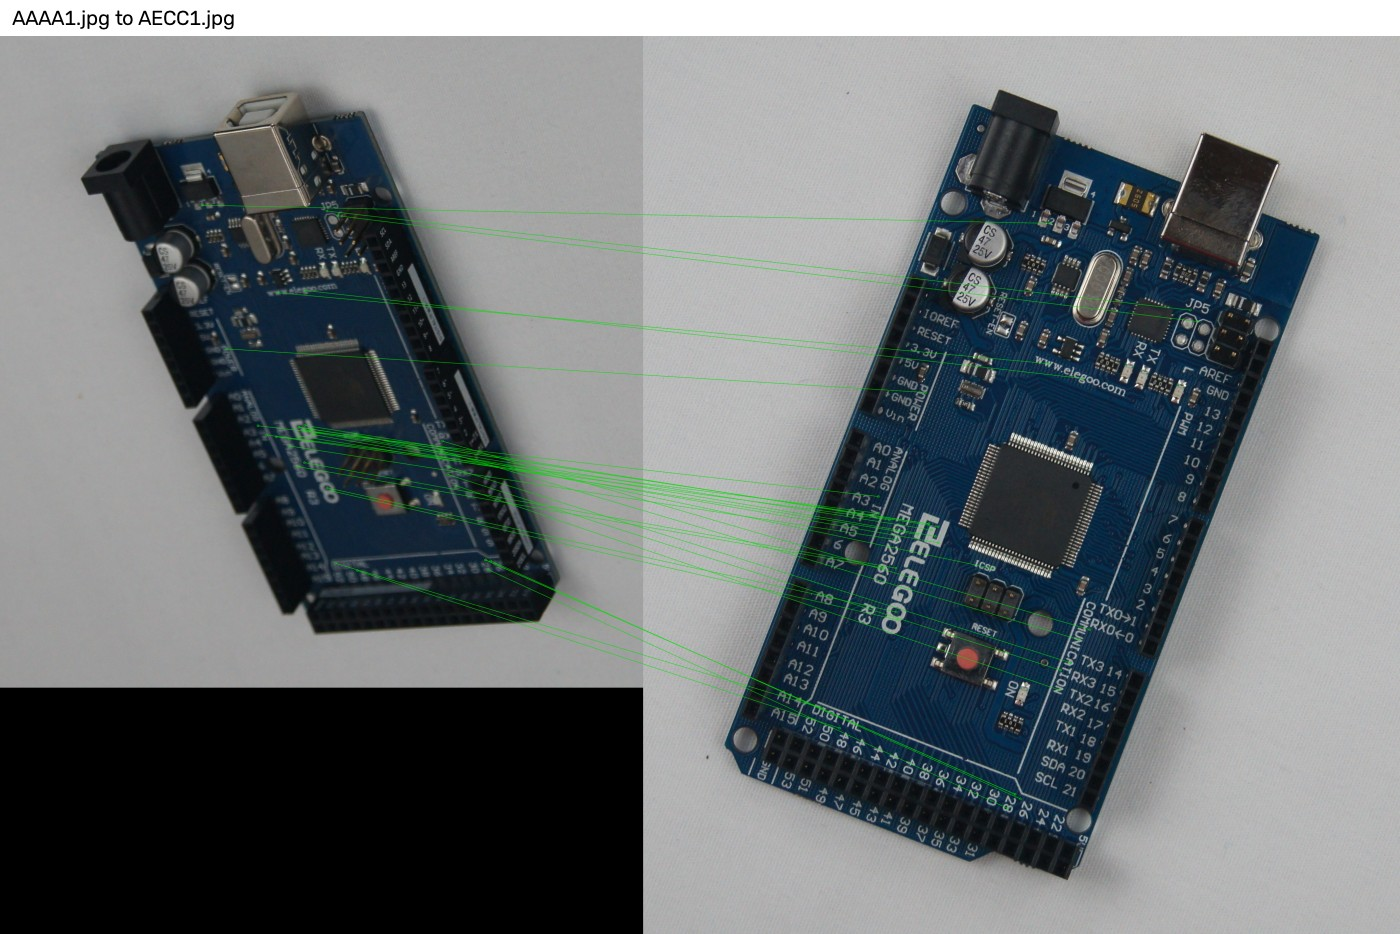

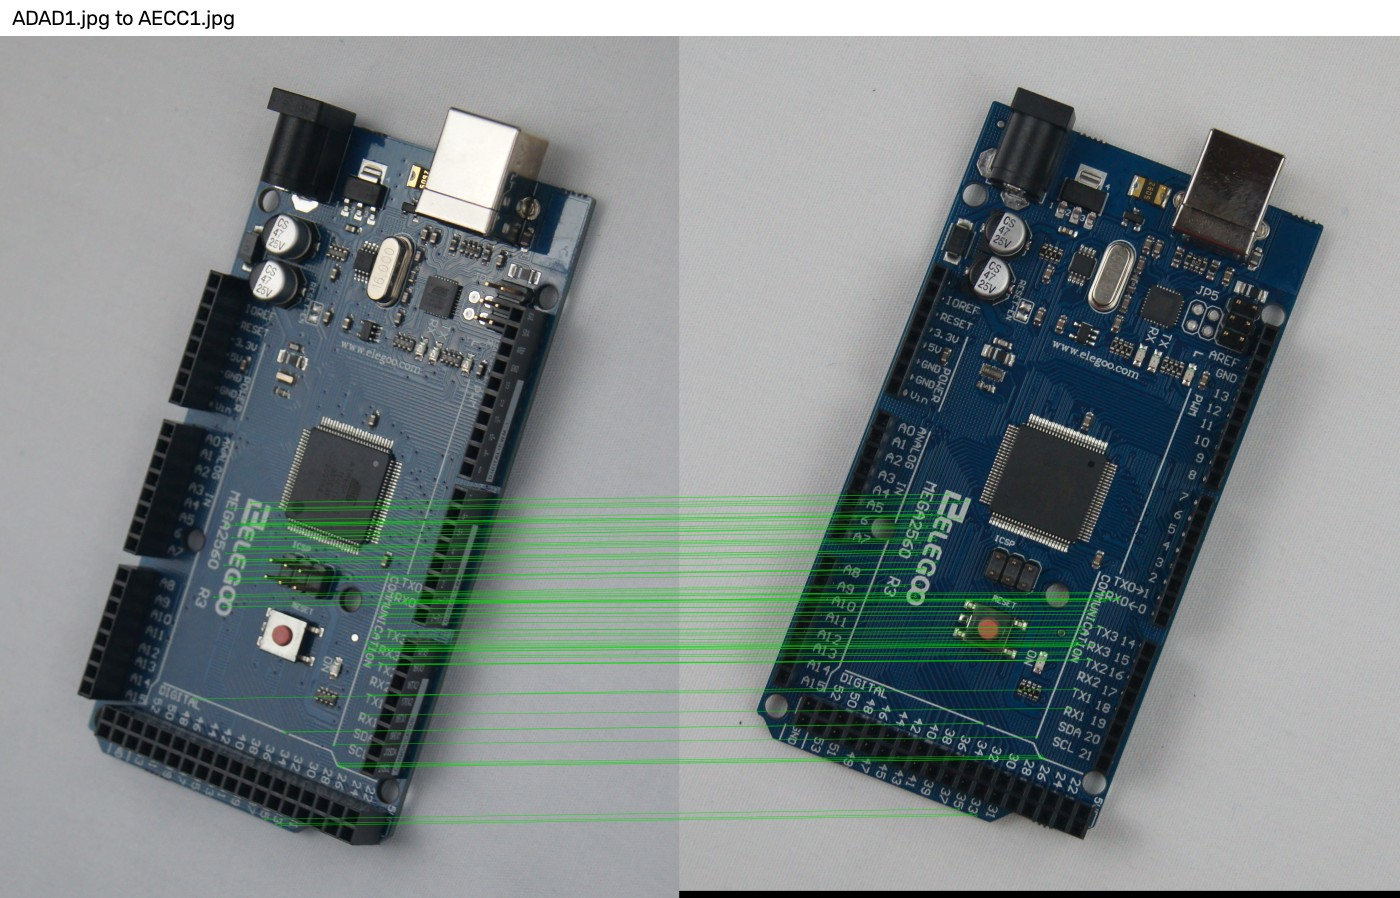

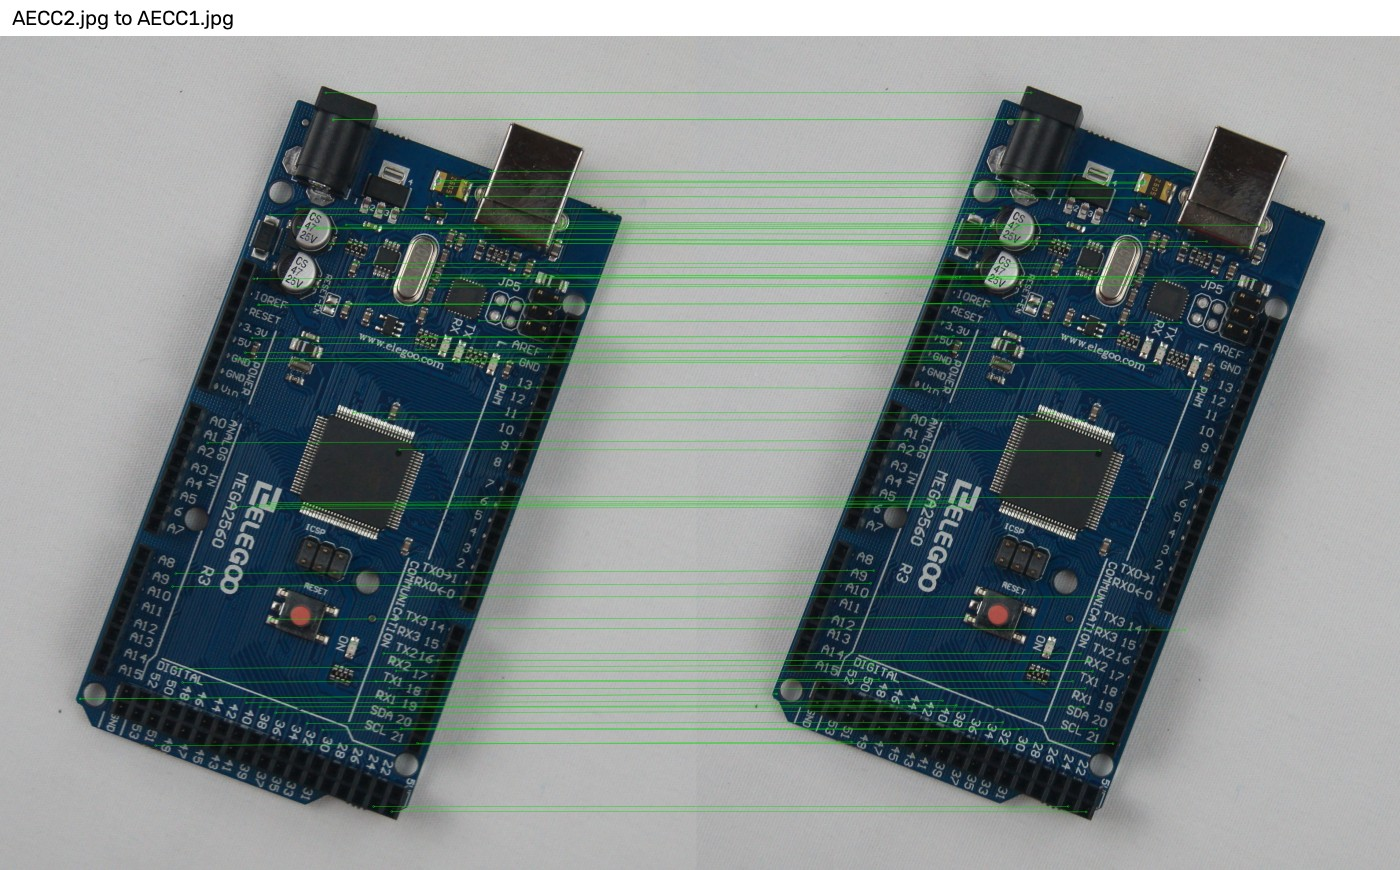

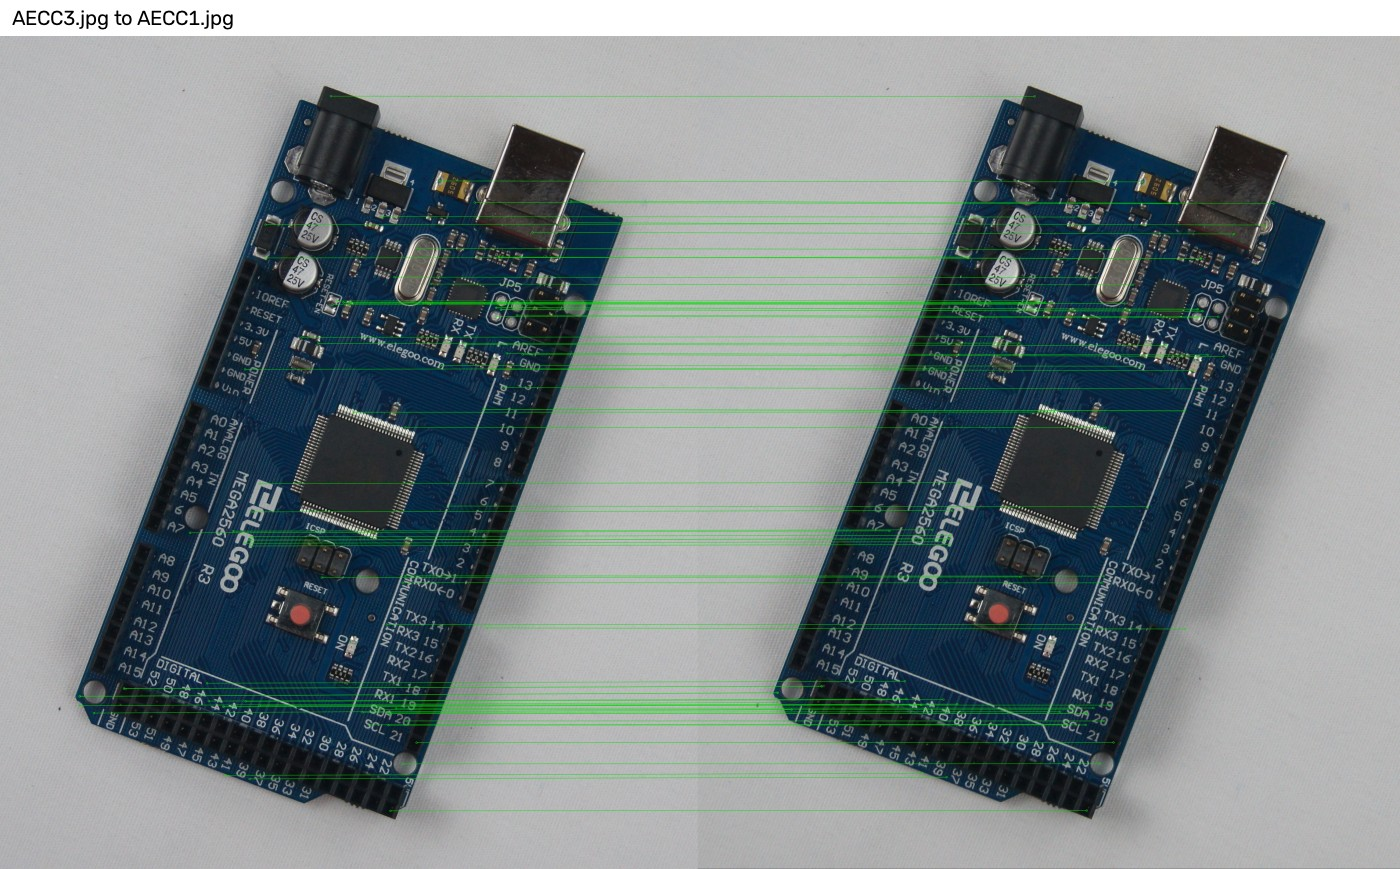

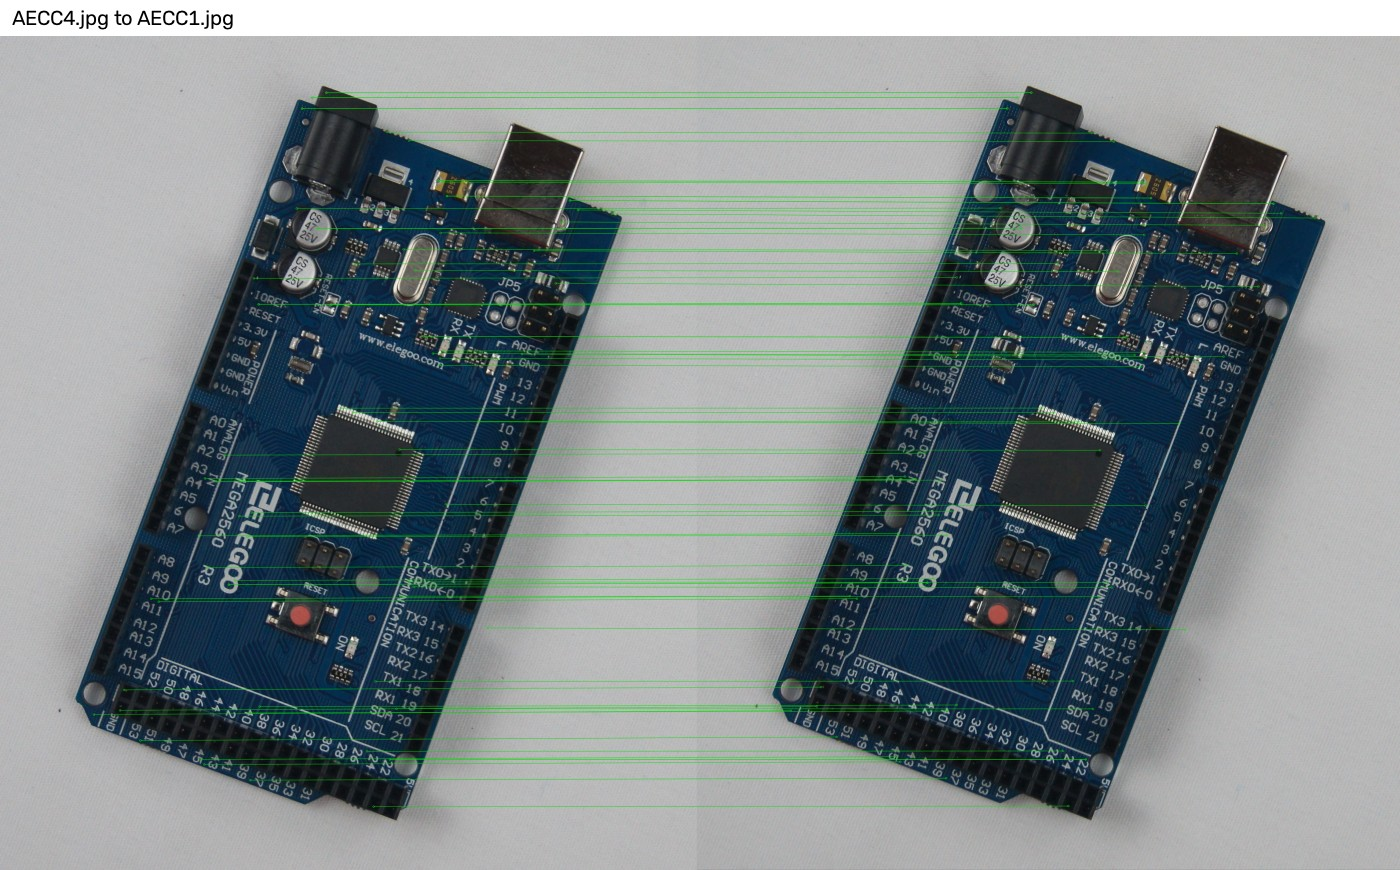

In [12]:
pcb_matches = json.loads((ROOT / "results/q4/matches_summary.json").read_text())
rows = "".join(f"<tr><td>{row['image']}</td><td>{row['match_count']}</td><td>{row['inlier_count']}</td></tr>" for row in pcb_matches)
display(HTML("<table><tr><th>PCB image</th><th>Filtered matches</th><th>RANSAC inliers</th></tr>" + rows + "</table>"))
for row in pcb_matches:
    name = Path(row["image"]).stem
    display(Image(filename=str(ROOT / f"results/q4/{name}_matches.jpg"), width=900))


The three AECC views give the largest inlier sets because their appearance is close to the reference image. AAAA1 gives the fewest inliers and has a more tilted view with less clear detail. The mutual match check prevents several source features from being assigned to one reference feature